In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_PATH = "../data/CS_S0_S1_S2_S3_S4_S6A_S6B_S6C_Person.dta"

In [2]:
raw = pd.read_stata(DATA_PATH, convert_categoricals=False)
print("rows, columns:", raw.shape)
print("households:", raw["hhid"].nunique())

rows, columns: (62110, 157)
households: 15054


In [3]:
# only people who attended school in the last 12 months were asked about school costs
students = raw[raw["s4aq7"] == 1].copy()

parts = ["s4aq14a", "s4aq14b", "s4aq14c", "s4aq14d", "s4aq14e", "s4aq14f", "s4aq14g"]
has_parts = students["s4aq14a"].notna()
has_total = students["s4aq14h"].notna()

print("students:", len(students))
print("with the 7 parts:", has_parts.sum(), "| with only the total:", has_total.sum())
print("with both:", (has_parts & has_total).sum(), "| with neither:", (~has_parts & ~has_total).sum())

students: 23094
with the 7 parts: 21431 | with only the total: 1663
with both: 0 | with neither: 0


In [4]:
students["expenditure"] = np.where(has_parts, students[parts].sum(axis=1), students["s4aq14h"])

print(students["expenditure"].describe().astype(int))
print("largest totals:", students["s4aq14h"].nlargest(5).tolist())

count      23094
mean       90079
std       287045
min          100
25%         9000
50%        15550
75%        50000
max      9999999
Name: expenditure, dtype: int64
largest totals: [9999999.0, 9999000.0, 9999000.0, 9040000.0, 8324000.0]


In [5]:
students = students[~students["expenditure"].isin([9_999_000, 9_999_999])]
print("students kept:", len(students))

students kept: 23091


In [6]:
SEX = {1: "Male", 2: "Female"}
PROVINCE = {1: "Kigali", 2: "Southern", 3: "Western", 4: "Northern", 5: "Eastern"}
AREA = {1: "Urban", 2: "Rural"}
LEVEL = {1: "ECD", 2: "Nursery", 3: "Primary", 5: "Lower secondary", 6: "Upper secondary", 7: "Tertiary"}
SCHOOL_TYPE = {1: "Public", 2: "Private", 3: "Government subsidized"}
BOARDING = {1: "Yes", 2: "No"}
# payers with very few students (state, organisation, employer, non-relatives, others) become "Other"
PAYER = {1: "Father", 2: "Mother", 3: "Both parents", 4: "Other household member", 5: "Other relative",
         7: "Self", 6: "Other", 8: "Other", 9: "Other", 10: "Other", 11: "Other"}

LEVEL_ORDER = list(LEVEL.values())

In [7]:
household_size = raw.groupby("hhid").size()

df = pd.DataFrame({
    "hhid": students["hhid"],
    "age": students["s1q3y"].astype(int),
    "sex": students["s1q1"].map(SEX),
    "province": students["province"].map(PROVINCE),
    "area": students["ur"].map(AREA),
    "school_level": students["s4aq8"].map(LEVEL),
    "school_type": students["s4aq11"].map(SCHOOL_TYPE),
    "boarding": students["s4aq8b"].map(BOARDING).fillna("Not applicable"),  # only asked in secondary
    "household_size": students["hhid"].map(household_size),
    "payer": students["s4aq15"].map(PAYER),
    "expenditure": students["expenditure"],
}).reset_index(drop=True)

print(df.shape)
print(df.isna().sum())
df.head()

(23091, 11)
hhid                0
age                 0
sex                 0
province            0
area                0
school_level        0
school_type         0
boarding            0
household_size      0
payer             232
expenditure         0
dtype: int64


,hhid,age,sex,province,area,school_level,school_type,boarding,household_size,payer,expenditure
0,300001.0,5,Male,Kigali,Urban,Nursery,Private,Not applicable,6,Father,164150.0
1,300004.0,17,Female,Kigali,Urban,Lower secondary,Public,No,4,Mother,96500.0
2,300004.0,14,Female,Kigali,Urban,Lower secondary,Private,Yes,4,Mother,573500.0
3,300005.0,13,Female,Kigali,Urban,Primary,Public,Not applicable,4,Both parents,64200.0
4,300005.0,12,Female,Kigali,Urban,Primary,Public,Not applicable,4,Both parents,60200.0


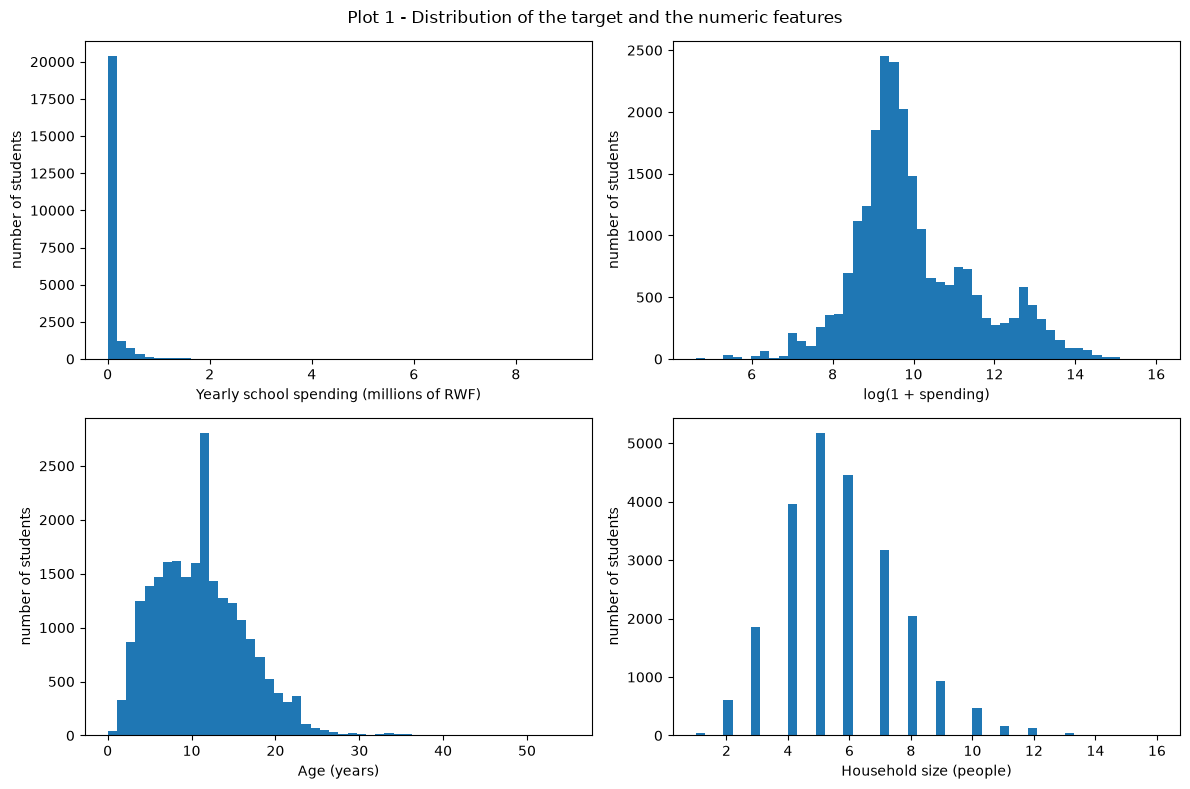

skewness before log: 11.11 | after log: 0.66


In [8]:
df["log_expenditure"] = np.log1p(df["expenditure"])

histograms = [
    (df["expenditure"] / 1_000_000, "Yearly school spending (millions of RWF)"),
    (df["log_expenditure"], "log(1 + spending)"),
    (df["age"], "Age (years)"),
    (df["household_size"], "Household size (people)"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (values, label) in zip(axes.ravel(), histograms):
    ax.hist(values, bins=50)
    ax.set_xlabel(label)
    ax.set_ylabel("number of students")
fig.suptitle("Plot 1 - Distribution of the target and the numeric features")
plt.tight_layout()
plt.show()

print("skewness before log:", round(df["expenditure"].skew(), 2), "| after log:", round(df["log_expenditure"].skew(), 2))

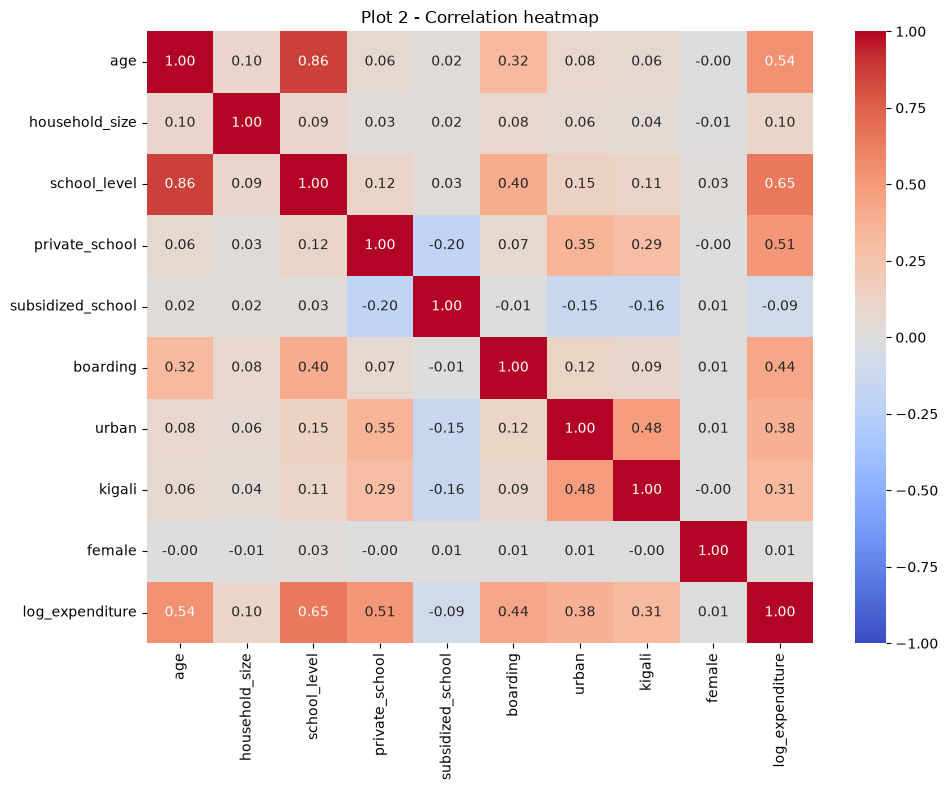

log_expenditure      1.00
school_level         0.65
age                  0.54
private_school       0.51
boarding             0.44
urban                0.38
kigali               0.31
household_size       0.10
female               0.01
subsidized_school   -0.09
Name: log_expenditure, dtype: float64


In [9]:
# yes/no versions of the categories so they can go in a correlation heatmap
heat = pd.DataFrame({
    "age": df["age"],
    "household_size": df["household_size"],
    "school_level": df["school_level"].map({level: i for i, level in enumerate(LEVEL_ORDER, start=1)}),
    "private_school": (df["school_type"] == "Private").astype(int),
    "subsidized_school": (df["school_type"] == "Government subsidized").astype(int),
    "boarding": (df["boarding"] == "Yes").astype(int),
    "urban": (df["area"] == "Urban").astype(int),
    "kigali": (df["province"] == "Kigali").astype(int),
    "female": (df["sex"] == "Female").astype(int),
    "log_expenditure": df["log_expenditure"],
})

plt.figure(figsize=(10, 8))
sns.heatmap(heat.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Plot 2 - Correlation heatmap")
plt.tight_layout()
plt.show()

print(heat.corr()["log_expenditure"].sort_values(ascending=False).round(2))